In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
df = pd.read_csv("position_salaries.csv")

print(df.head())
print(df.info())
print(df.describe())

   Level    Salary
0      1   47400.0
1      2   69200.0
2      3  106500.0
3      4  154200.0
4      5  259700.0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Level   10 non-null     int64  
 1   Salary  10 non-null     float64
dtypes: float64(1), int64(1)
memory usage: 288.0 bytes
None
          Level        Salary
count  10.00000  1.000000e+01
mean    5.50000  6.393800e+05
std     3.02765  7.360576e+05
min     1.00000  4.740000e+04
25%     3.25000  1.184250e+05
50%     5.50000  3.292000e+05
75%     7.75000  8.858000e+05
max    10.00000  2.249500e+06


In [3]:
X = df[["Level"]]
y = df["Salary"]

In [4]:
poly = PolynomialFeatures(degree=4)

X_poly = poly.fit_transform(X)

model = LinearRegression()
model.fit(X_poly, y)

LinearRegression()

In [5]:
y_pred = model.predict(X_poly)

comparison = pd.DataFrame({
    "Actual Salary": y,
    "Predicted Salary": y_pred
})

print(comparison)

   Actual Salary  Predicted Salary
0        47400.0      4.643811e+04
1        69200.0      7.051434e+04
2       106500.0      1.061595e+05
3       154200.0      1.607428e+05
4       259700.0      2.492136e+05
5       398700.0      3.941013e+05
6       614000.0      6.255152e+05
7       976400.0      9.811449e+05
8      1518200.0      1.506260e+06
9      2249500.0      2.253710e+06


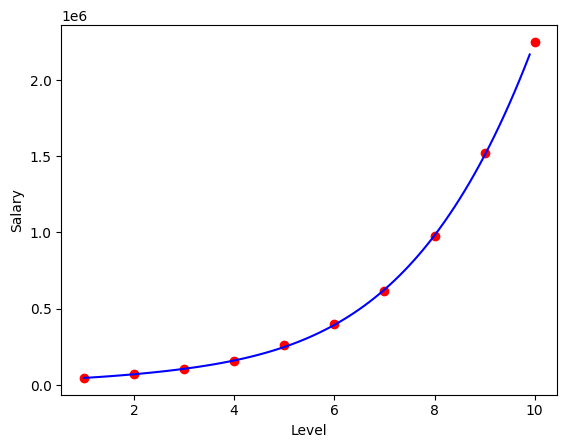

In [10]:
X_grid = pd.DataFrame({"Level": np.arange(1, 10, 0.1)})

y_grid_pred = model.predict(poly.transform(X_grid))

plt.scatter(X, y, color="red")
plt.plot(X_grid, y_grid_pred, color="blue")

plt.xlabel("Level")
plt.ylabel("Salary")
plt.show()

In [7]:
print("MSE:", mean_squared_error(y, y_pred))
print("R2 Score:", r2_score(y, y_pred))

MSE: 49209206.87645668
R2 Score: 0.9998990793117958


In [8]:
new_level = pd.DataFrame({"Level": [6.5]})
new_level_poly = poly.transform(new_level)
predicted_salary = model.predict(new_level_poly)
print("Predicted Salary:", predicted_salary[0])

Predicted Salary: 496814.5241477275
